# MedTwin AI — Phase 4: 3D Tumor Mesh Reconstruction & Interactive Viewer

**Project:** MedTwin AI — AI-Based Multi-Disease Brain MRI 3D Reconstruction and Volumetry

**Phase 4 objective:** build a **patient-specific 3D digital twin** of the tumor — a real 3D surface
mesh reconstructed from *that particular patient's own* AI-predicted segmentation — and view it
interactively. This is **not** a fixed/generic/template brain shape; every mesh here is generated
fresh from the actual voxel data of the patient you select in Cell 2.

Pipeline covered here: **trained model → per-patient inference (same as Phase 3) → 3D surface mesh
per tumor sub-region (marching cubes, real mm coordinates from that patient's own scan) →
interactive viewer → saved mesh files.**

This notebook is self-contained: it reruns inference internally (same model bundle, same
preprocessing, same patient-selection logic as Phase 3) so it doesn't depend on Phase 3 having saved
any extra files — only the Phase 2 `model_bundle.json` and the dataset are required.

This notebook does **not**:
- Use any fixed/template/atlas brain shape — geometry always comes from the selected patient's own
  predicted segmentation.
- Build the web application or dashboard (a later phase).
- Generate a narrative clinical report.
- Make any clinical or diagnostic claim — this is a research prototype.

**Assumption:** as with Phase 3, no detailed spec was given for this phase, so it follows your
original roadmap's next step (3D reconstruction + interactive viewer, using Phase 2/3's model and
volume outputs as input). Let me know if you had something more specific in mind.


## Cell 1 — Environment Verification & Device Selection

Adds `scikit-image` (marching cubes surface extraction) and `plotly` (interactive 3D rendering,
works natively inline in Jupyter) to the checks used in Phases 2–3.


In [52]:
import sys
import importlib
from importlib.metadata import version as pkg_version, PackageNotFoundError

def check_environment():
    required = ["torch", "monai", "numpy", "nibabel", "pandas", "skimage", "plotly"]
    display_names = {"skimage": "scikit-image"}
    rows = [("python", sys.version.split()[0], "Available")]
    for name in required:
        try:
            module = importlib.import_module(name)
            pkg_name = display_names.get(name, name)
            try:
                ver = pkg_version(pkg_name)
            except PackageNotFoundError:
                ver = getattr(module, "__version__", "unknown")
            rows.append((pkg_name, ver, "Available"))
        except ImportError:
            rows.append((display_names.get(name, name), "-", "Missing"))

    name_w = max(len(r[0]) for r in rows) + 2
    ver_w = max(len(str(r[1])) for r in rows) + 2
    print("Environment Check")
    print("-" * (name_w + ver_w + 12))
    for name, ver, status in rows:
        print(f"{name:<{name_w}}{str(ver):<{ver_w}}{status}")

    missing = [r[0] for r in rows if r[2] == "Missing"]
    if missing:
        print("\nMissing packages:", ", ".join(missing))
        print("Install with: pip install " + " ".join(missing))
    else:
        print("\nAll required packages are available.")

check_environment()


Environment Check
----------------------------------------
python        3.11.15       Available
torch         2.13.0+cu126  Available
monai         1.6.0         Available
numpy         1.26.4        Available
nibabel       5.4.2         Available
pandas        3.0.5         Available
scikit-image  0.26.0        Available
plotly        7.0.0         Available

All required packages are available.


In [53]:
import torch

def select_device():
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"CUDA available — using GPU: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("CUDA not available — using CPU.")
    return device

DEVICE = select_device()
print(f"\nSelected device: {DEVICE}")


CUDA available — using GPU: NVIDIA GeForce MX550

Selected device: cuda


In [54]:
import pandas as pd
import json

print(f"pandas version: {pd.__version__}")


pandas version: 3.0.5


## Cell 2 — Paths and Patient Selection

Same pattern as Phase 3: `MODEL_BUNDLE_PATH` points at Phase 2's saved bundle (architecture, label
mapping, preprocessing config, train/val/test split). Set `INFERENCE_MODE` and the patient identity
— **this choice determines whose actual scan the 3D mesh is built from**; nothing here is a
template or shared shape.


In [69]:
from pathlib import Path

# ----- EDIT THESE -----
OUTPUT_DIR = Path(r"C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs")
MODEL_BUNDLE_PATH = OUTPUT_DIR / "model_bundle" / "model_bundle.json"

INFERENCE_MODE = "test_patient"  # "test_patient" or "new_patient"

# Used only if INFERENCE_MODE == "test_patient": which patient from the saved test split.
# None -> automatically use the first test-split patient found on disk.
TEST_PATIENT_ID = None

# Used only if INFERENCE_MODE == "new_patient": folder containing that patient's modality files.
NEW_PATIENT_DIR = Path(r"C:\Users\admin\Desktop\Med_Twin\Dataset\NewPatient001")
# ------------------------

MESH_DIR = OUTPUT_DIR / "phase4_meshes"
MESH_DIR.mkdir(parents=True, exist_ok=True)

print(f"OUTPUT_DIR:         {OUTPUT_DIR}")
print(f"MODEL_BUNDLE_PATH:  {MODEL_BUNDLE_PATH}")
print(f"INFERENCE_MODE:     {INFERENCE_MODE}")
print(f"MESH_DIR:           {MESH_DIR}")

if not MODEL_BUNDLE_PATH.exists():
    print(
        f"\nWARNING: model bundle not found at {MODEL_BUNDLE_PATH}\n"
        "Run Phase 2 through Cell 22 (Save Model and Configuration) first, or update this path."
    )


OUTPUT_DIR:         C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs
MODEL_BUNDLE_PATH:  C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\model_bundle\model_bundle.json
INFERENCE_MODE:     test_patient
MESH_DIR:           C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes


## Cell 3 — Load the Model Bundle


In [70]:
def load_model_bundle(path: Path):
    if not path.exists():
        print(f"Model bundle not found: {path}")
        return None
    with open(path, "r") as f:
        bundle = json.load(f)
    return bundle

model_bundle = load_model_bundle(MODEL_BUNDLE_PATH)

if model_bundle is not None:
    print("Loaded model bundle")
    print("-" * 40)
    print(f"Checkpoint path:      {model_bundle['checkpoint_path']}")
    print(f"Input modalities:     {model_bundle['model_config']['modality_order']}")
    print(f"Label mapping:        {model_bundle['label_mapping']}")
    print(f"Test-set patients:    {len(model_bundle['split_info']['test_patients'])}")
else:
    print("Cannot proceed without a model bundle — check MODEL_BUNDLE_PATH in Cell 2.")


Loaded model bundle
----------------------------------------
Checkpoint path:      C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth
Input modalities:     ['t1', 't1c', 't2', 'flair']
Label mapping:        {'0': 'background', '1': 'necrotic_core', '2': 'edema', '3': 'enhancing_tumor'}
Test-set patients:    188


## Cell 4 — Rebuild Inference Preprocessing

Same robust approach as Phase 3: reads settings from the bundle, with fallbacks for older bundles
that predate certain saved fields (e.g. `divisible_pad_factor` computed from the model's own
strides if not present).


In [71]:
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    NormalizeIntensityd, CropForegroundd, ConcatItemsd, DeleteItemsd, EnsureTyped, DivisiblePadd
)

MODALITY_FILENAME_SUFFIXES = {
    "t1": "-t1n.nii.gz",
    "t1c": "-t1c.nii.gz",
    "t2": "-t2w.nii.gz",
    "flair": "-t2f.nii.gz",
}
LABEL_FILENAME_SUFFIX = "-seg.nii.gz"

MODALITY_KEYS = model_bundle["model_config"]["modality_order"] if model_bundle else list(MODALITY_FILENAME_SUFFIXES)
LABEL_KEY = "seg"

def get_divisible_pad_factor(bundle):
    cfg = bundle["preprocessing_config"]
    if "divisible_pad_factor" in cfg:
        return cfg["divisible_pad_factor"]
    strides = bundle["model_config"].get("strides", [2, 2, 2])
    factor = 1
    for s in strides:
        factor *= s
    print(f"NOTE: 'divisible_pad_factor' not found in the saved bundle — computed {factor} "
          f"from model_config['strides']={strides} instead.")
    return factor

def build_inference_transforms(bundle):
    cfg = bundle["preprocessing_config"]
    all_keys = MODALITY_KEYS + [LABEL_KEY]

    target_orientation = cfg.get("target_orientation", "RAS")
    target_spacing_mm = cfg.get("target_spacing_mm", [1.0, 1.0, 1.0])
    divisible_pad_factor = get_divisible_pad_factor(bundle)

    return Compose([
        LoadImaged(keys=all_keys, image_only=True, allow_missing_keys=True),
        EnsureChannelFirstd(keys=all_keys, allow_missing_keys=True),
        Orientationd(keys=all_keys, axcodes=target_orientation, allow_missing_keys=True),
        Spacingd(
            keys=all_keys, pixdim=tuple(target_spacing_mm),
            mode=["bilinear"] * len(MODALITY_KEYS) + ["nearest"],
            allow_missing_keys=True,
        ),
        NormalizeIntensityd(keys=MODALITY_KEYS, nonzero=True, channel_wise=True),
        ConcatItemsd(keys=MODALITY_KEYS, name="image"),
        DeleteItemsd(keys=MODALITY_KEYS),
        CropForegroundd(keys=["image", LABEL_KEY], source_key="image", allow_missing_keys=True),
        DivisiblePadd(keys=["image", LABEL_KEY], k=divisible_pad_factor, allow_missing_keys=True),
        EnsureTyped(keys=["image", LABEL_KEY], allow_missing_keys=True, track_meta=True),
    ])

inference_transforms = build_inference_transforms(model_bundle) if model_bundle else None
if inference_transforms is not None:
    print("Inference preprocessing pipeline created.")


NOTE: 'divisible_pad_factor' not found in the saved bundle — computed 8 from model_config['strides']=[2, 2, 2] instead.
Inference preprocessing pipeline created.


C:\Users\admin\anaconda3\envs\Medtwin\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


## Cell 5 — Rebuild Model Architecture and Load Trained Weights


In [72]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm

def build_model_from_config(model_config, device):
    return UNet(
        spatial_dims=model_config["spatial_dims"],
        in_channels=model_config["in_channels"],
        out_channels=model_config["out_channels"],
        channels=tuple(model_config["channels"]),
        strides=tuple(model_config["strides"]),
        num_res_units=model_config["num_res_units"],
        norm=Norm.BATCH,
    ).to(device)

def resolve_checkpoint_path(bundle, output_dir):
    '''Use the bundle's saved checkpoint path if it still exists; otherwise fall back to the
    standard OUTPUT_DIR/checkpoints/best_model.pth location. Keeps this working even if the
    project folder has been moved/renamed since Phase 2 saved the bundle.'''
    saved_path = Path(bundle["checkpoint_path"])
    if saved_path.exists():
        return saved_path

    fallback_path = output_dir / "checkpoints" / "best_model.pth"
    if fallback_path.exists():
        print(f"NOTE: bundle's saved checkpoint path no longer exists:\n  {saved_path}\n"
              f"Using the checkpoint found at the standard location instead:\n  {fallback_path}")
        return fallback_path

    return saved_path  # neither exists; return original so the error message below is accurate

model = None
model_loaded_ok = False

if model_bundle is not None:
    model = build_model_from_config(model_bundle["model_config"], DEVICE)
    ckpt_path = resolve_checkpoint_path(model_bundle, OUTPUT_DIR)

    if not ckpt_path.exists():
        print(f"Checkpoint file not found: {ckpt_path}")
        print(f"Also checked standard location: {OUTPUT_DIR / 'checkpoints' / 'best_model.pth'}")
        print("Make sure OUTPUT_DIR in Cell 2 points at your current project folder.")
    else:
        state_dict = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(state_dict, strict=True)
        model.eval()
        model_loaded_ok = True
        print("Model loaded successfully")
        print("-" * 40)
        print(f"Checkpoint: {ckpt_path}")
        print(f"Device:     {DEVICE}")
else:
    print("No model bundle available — cannot build model.")


NOTE: bundle's saved checkpoint path no longer exists:
  C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth
Using the checkpoint found at the standard location instead:
  C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\checkpoints\best_model.pth
Model loaded successfully
----------------------------------------
Checkpoint: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\checkpoints\best_model.pth
Device:     cuda


## Cell 6 — Locate and Preprocess the Selected Patient

Finds this **specific patient's** own modality files and preprocesses them. Whatever patient is
chosen here is whose real anatomy the 3D mesh will reflect later in this notebook.


In [73]:
def find_patient_files(patient_dir: Path, modality_suffixes, label_suffix=None):
    result = {}
    for key, suffix in modality_suffixes.items():
        matches = list(patient_dir.glob(f"*{suffix}"))
        result[key] = str(matches[0]) if matches else None
    if label_suffix is not None:
        seg_matches = list(patient_dir.glob(f"*{label_suffix}"))
        result[LABEL_KEY] = str(seg_matches[0]) if seg_matches else None
    return result

target_patient_id = None
patient_data_dict = None
has_ground_truth = False

if model_bundle is not None:
    if INFERENCE_MODE == "test_patient":
        test_patients = model_bundle["split_info"]["test_patients"]
        if not test_patients:
            print("No test patients recorded in the model bundle's split_info.")
        else:
            target_patient_id = TEST_PATIENT_ID or test_patients[0]
            candidate_dirs = []
            for base in [OUTPUT_DIR.parent, OUTPUT_DIR]:
                candidate_dirs.extend(base.rglob(target_patient_id))

            # A directory can be *named* after the patient without *containing* their scan files
            # (e.g. this notebook's own MESH_DIR/<patient_id>/ output folder from a prior run).
            # Validate each candidate by actually checking for the modality files, rather than
            # trusting the first directory match by name alone.
            patient_dir = None
            for candidate in candidate_dirs:
                if not candidate.is_dir():
                    continue
                probe = find_patient_files(candidate, MODALITY_FILENAME_SUFFIXES, LABEL_FILENAME_SUFFIX)
                if all(probe.get(k) is not None for k in MODALITY_KEYS):
                    patient_dir = candidate
                    break

            if patient_dir is None:
                print(f"Could not locate folder for test patient '{target_patient_id}' automatically. "
                      f"Set TEST_PATIENT_ID, or switch to INFERENCE_MODE='new_patient'.")
            else:
                patient_data_dict = find_patient_files(patient_dir, MODALITY_FILENAME_SUFFIXES, LABEL_FILENAME_SUFFIX)
                has_ground_truth = patient_data_dict.get(LABEL_KEY) is not None

    elif INFERENCE_MODE == "new_patient":
        if not NEW_PATIENT_DIR.exists():
            print(f"NEW_PATIENT_DIR does not exist: {NEW_PATIENT_DIR}")
        else:
            target_patient_id = NEW_PATIENT_DIR.name
            patient_data_dict = find_patient_files(NEW_PATIENT_DIR, MODALITY_FILENAME_SUFFIXES)
            has_ground_truth = False
    else:
        print(f"Unknown INFERENCE_MODE: {INFERENCE_MODE!r}")

if patient_data_dict is not None:
    missing_modalities = [k for k in MODALITY_KEYS if patient_data_dict.get(k) is None]
    if missing_modalities:
        print(f"Cannot proceed — missing required modalities: {missing_modalities}")
        patient_data_dict = None
    else:
        print(f"Target patient: {target_patient_id}")
        print(f"Ground truth available: {has_ground_truth}")

preprocessed_sample = None
if patient_data_dict is not None and inference_transforms is not None:
    input_dict = {k: v for k, v in patient_data_dict.items() if v is not None}
    preprocessed_sample = inference_transforms(input_dict)
    print(f"Preprocessed image shape: {tuple(preprocessed_sample['image'].shape)}")


Target patient: BraTS-GLI-00449-000
Ground truth available: True
Preprocessed image shape: (4, 144, 160, 144)


## Cell 7 — Run Inference on This Patient's Scan

Produces the predicted label volume that the 3D mesh will be built from — this array is unique to
the patient selected in Cell 2, not a fixed template.


In [74]:
from monai.inferers import SlidingWindowInferer

INFERENCE_ROI_SIZE = tuple(model_bundle["preprocessing_config"].get("train_patch_size", [96, 96, 96])) \
    if model_bundle else (96, 96, 96)
sliding_inferer = SlidingWindowInferer(roi_size=INFERENCE_ROI_SIZE, sw_batch_size=1,
                                        overlap=0.5, mode="gaussian")

prediction_labels = None

if model_loaded_ok and preprocessed_sample is not None:
    image_batch = preprocessed_sample["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        output_logits = sliding_inferer(image_batch, model)
        prediction_labels = torch.argmax(torch.softmax(output_logits, dim=1), dim=1).squeeze(0).cpu()

    print(f"Inference complete for patient: {target_patient_id}")
    print(f"Prediction shape: {tuple(prediction_labels.shape)}")
    print(f"Unique predicted labels: {torch.unique(prediction_labels).tolist()}")
else:
    print("Cannot run inference — model or preprocessed input not available.")


Inference complete for patient: BraTS-GLI-00449-000
Prediction shape: (144, 160, 144)
Unique predicted labels: [0, 1, 2, 3]


## Cell 8 — Extract 3D Surface Meshes (Marching Cubes)

For each non-background predicted label, run **marching cubes** (`skimage.measure.marching_cubes`)
on that label's binary mask to extract a real 3D surface — vertices and triangular faces — directly
from this patient's own predicted voxels.

Vertex coordinates are converted to **physical millimeters** using the preprocessed volume's own
affine (voxel spacing), not left as raw array indices, so the mesh has a true physical scale.

A very light Gaussian smoothing is applied to the binary mask *before* marching cubes purely to
soften voxel "staircase" edges for a more legible 3D surface — this is a **visualization aid only**;
it does not alter the voxel-based volume numbers already reported in Phase 3.


In [75]:
import numpy as np
from skimage.measure import marching_cubes
from scipy.ndimage import gaussian_filter

def voxel_to_mm(vertices_voxel, affine):
    '''Transform Nx3 voxel-index vertices to physical mm coordinates using the affine.'''
    n = vertices_voxel.shape[0]
    homogeneous = np.hstack([vertices_voxel, np.ones((n, 1))])
    mm = (affine @ homogeneous.T).T[:, :3]
    return mm

def extract_label_mesh(pred_array, label_value, affine, smoothing_sigma=0.6):
    '''Extract a surface mesh for one label from this patient's own predicted volume.
    Returns None if the label is not present (no fabricated geometry for absent regions).'''
    binary_mask = (pred_array == label_value).astype(np.float32)
    if binary_mask.sum() == 0:
        return None

    padded = np.pad(binary_mask, pad_width=1, mode="constant", constant_values=0)
    smoothed = gaussian_filter(padded, sigma=smoothing_sigma)

    try:
        verts_voxel, faces, normals, _ = marching_cubes(smoothed, level=0.5)
    except (ValueError, RuntimeError) as e:
        print(f"  Could not extract a surface for label {label_value}: {e}")
        return None

    verts_voxel -= 1  # undo the padding offset
    verts_mm = voxel_to_mm(verts_voxel, affine)

    return {"vertices_mm": verts_mm, "faces": faces, "normals": normals,
            "voxel_count": int(binary_mask.sum())}

meshes = {}
if prediction_labels is not None and model_bundle is not None:
    pred_np = prediction_labels.numpy()
    affine = preprocessed_sample["image"].affine.numpy() if hasattr(preprocessed_sample["image"], "affine") \
        else np.eye(4)

    print(f"Extracting per-label 3D surfaces for patient: {target_patient_id}")
    print("-" * 40)
    for label_value_str, label_name in model_bundle["label_mapping"].items():
        label_value = int(label_value_str)
        if label_value == 0:
            continue

        mesh = extract_label_mesh(pred_np, label_value, affine)
        if mesh is None:
            print(f"{label_name} (label {label_value}): not present in prediction — no mesh generated")
            continue

        meshes[label_name] = mesh
        print(f"{label_name} (label {label_value}): {mesh['vertices_mm'].shape[0]:,} vertices, "
              f"{mesh['faces'].shape[0]:,} faces")

    if not meshes:
        print("\nNo tumor regions predicted for this patient — nothing to reconstruct.")
else:
    print("No prediction available — run Cell 7 first.")


Extracting per-label 3D surfaces for patient: BraTS-GLI-00449-000
----------------------------------------
necrotic_core (label 1): 18,091 vertices, 36,182 faces
edema (label 2): 56,768 vertices, 113,612 faces
enhancing_tumor (label 3): 36,901 vertices, 73,962 faces


## Cell 8a — Extract Ground-Truth Meshes for Comparison (If Available)

**This is the key step for checking whether the model is actually correct.** A good-looking 3D
shape doesn't by itself prove the size or shape is right — the only real way to check that is to
compare the AI's prediction against the **known correct answer** for a labeled scan.

If ground truth is available (`test_patient` mode with a labeled patient), this extracts the same
kind of mesh from the ground-truth segmentation, so Cell 10's viewer can show prediction and ground
truth side by side, and Cell 9's table can report exactly how far off each region's volume is from
the true value — not just internal consistency checks.


In [76]:
gt_meshes = {}

if has_ground_truth and prediction_labels is not None and LABEL_KEY in preprocessed_sample:
    gt_np = preprocessed_sample[LABEL_KEY][0].numpy().astype(np.int64)

    print(f"Extracting ground-truth 3D surfaces for patient: {target_patient_id}")
    print("-" * 40)
    for label_value_str, label_name in model_bundle["label_mapping"].items():
        label_value = int(label_value_str)
        if label_value == 0:
            continue

        gt_mesh = extract_label_mesh(gt_np, label_value, affine)
        if gt_mesh is None:
            print(f"{label_name} (label {label_value}): not present in ground truth")
            continue

        gt_meshes[label_name] = gt_mesh
        print(f"{label_name} (label {label_value}): {gt_mesh['vertices_mm'].shape[0]:,} vertices "
              f"(ground truth)")
else:
    print("No ground truth available for this patient — skipping "
          "(expected in 'new_patient' mode; for a real correctness check, run this in "
          "'test_patient' mode on a labeled scan).")


Extracting ground-truth 3D surfaces for patient: BraTS-GLI-00449-000
----------------------------------------
necrotic_core (label 1): 14,633 vertices (ground truth)
edema (label 2): 53,660 vertices (ground truth)
enhancing_tumor (label 3): 34,107 vertices (ground truth)


## Cell 8b — Extract a Whole-Brain Outline (From This Patient's Own Scan)

The tumor meshes above float in empty space with no surrounding context, which doesn't look like a
real brain. To fix that, this cell extracts a rough **whole-brain outline** — and, like everything
else in this notebook, it comes from **this patient's own scan**, not a template or atlas brain.

This works because BraTS scans are already skull-stripped: every non-brain voxel (skull, scalp,
background) is exactly zero, and every brain voxel is non-zero. So the "brain shape" is simply the
non-zero region of the patient's own preprocessed image — found here as the largest connected
non-zero component (to drop any stray noise), with small internal holes filled in so it forms one
solid shell rather than a hollow shell with gaps.

If you're running this on a scan that was **not** already skull-stripped (e.g. a raw new-patient
scan with skull/scalp still present), this simple nonzero-based extraction will include the skull
too — a real skull-stripping step (e.g. HD-BET, SynthStrip) would be needed for accurate results in
that case. This is flagged below if detected.


In [77]:
from scipy.ndimage import label as cc_label, binary_fill_holes

def extract_brain_outline_mesh(image_tensor, affine, nonzero_eps=1e-3, smoothing_sigma=1.0):
    '''Extract a rough whole-brain surface from THIS patient's own preprocessed image, using the
    fact that BraTS scans are pre-skull-stripped (background voxels are exactly 0). Returns None
    if no clear single foreground region is found.'''
    arr = image_tensor.numpy()
    nonzero_any_modality = np.any(np.abs(arr) > nonzero_eps, axis=0)

    if nonzero_any_modality.sum() == 0:
        return None, None

    labeled, num_components = cc_label(nonzero_any_modality)
    if num_components == 0:
        return None, None

    component_sizes = [np.sum(labeled == i) for i in range(1, num_components + 1)]
    largest_component_id = 1 + int(np.argmax(component_sizes))
    brain_mask = (labeled == largest_component_id)
    brain_mask = binary_fill_holes(brain_mask).astype(np.float32)

    foreground_fraction = brain_mask.sum() / brain_mask.size
    likely_not_skull_stripped = foreground_fraction > 0.55  # a full head fills much more of the volume

    padded = np.pad(brain_mask, pad_width=1, mode="constant", constant_values=0)
    smoothed = gaussian_filter(padded, sigma=smoothing_sigma)

    try:
        verts_voxel, faces, normals, _ = marching_cubes(smoothed, level=0.5)
    except (ValueError, RuntimeError) as e:
        print(f"Could not extract a brain surface: {e}")
        return None, None

    verts_voxel -= 1
    verts_mm = voxel_to_mm(verts_voxel, affine)

    mesh = {"vertices_mm": verts_mm, "faces": faces, "normals": normals,
            "voxel_count": int(brain_mask.sum())}
    return mesh, likely_not_skull_stripped

brain_mesh = None
if preprocessed_sample is not None:
    brain_mesh, likely_not_skull_stripped = extract_brain_outline_mesh(
        preprocessed_sample["image"], affine
    )

    if brain_mesh is not None:
        print(f"Brain outline extracted: {brain_mesh['vertices_mm'].shape[0]:,} vertices, "
              f"{brain_mesh['faces'].shape[0]:,} faces")
        if likely_not_skull_stripped:
            print(
                "\nWARNING: the non-zero region covers most of the volume, which usually means "
                "this scan still has the skull/scalp present (not pre-skull-stripped like BraTS "
                "training data). The extracted 'brain' outline may actually be the whole head. "
                "For an accurate brain-only shape on such scans, run a real skull-stripping tool "
                "(e.g. HD-BET, SynthStrip) before this notebook."
            )
    else:
        print("Could not extract a brain outline for this patient.")
else:
    print("No preprocessed image available — run Cell 6 first.")


Brain outline extracted: 107,588 vertices, 215,172 faces


## Cell 9 — Mesh Volume Cross-Check (Sanity Check)

Compute each mesh's enclosed volume directly from its triangles (divergence theorem) and compare it
to Phase 3's voxel-counting volume for the same label. They should be close but **not identical** —
marching cubes reconstructs a smooth surface, so small differences (typically a few percent) are
expected and normal, not a bug.


In [78]:
def mesh_signed_volume_mm3(vertices, faces):
    '''Closed-mesh volume via the divergence theorem (signed tetrahedron volumes from the origin).'''
    v0 = vertices[faces[:, 0]]
    v1 = vertices[faces[:, 1]]
    v2 = vertices[faces[:, 2]]
    signed_vols = np.sum(v0 * np.cross(v1, v2), axis=1) / 6.0
    return abs(signed_vols.sum())

def voxel_volume_mm3_from_affine(affine):
    return float(np.abs(np.linalg.det(affine[:3, :3])))

cross_check_rows = []
if meshes and prediction_labels is not None:
    voxel_vol_mm3 = voxel_volume_mm3_from_affine(affine)

    for label_name, mesh in meshes.items():
        mesh_vol_mm3 = mesh_signed_volume_mm3(mesh["vertices_mm"], mesh["faces"])
        voxel_vol_mm3_total = mesh["voxel_count"] * voxel_vol_mm3
        pct_diff = 100 * (mesh_vol_mm3 - voxel_vol_mm3_total) / voxel_vol_mm3_total if voxel_vol_mm3_total else 0.0

        cross_check_rows.append({
            "region": label_name,
            "voxel_based_volume_cm3": round(voxel_vol_mm3_total / 1000.0, 4),
            "mesh_based_volume_cm3": round(mesh_vol_mm3 / 1000.0, 4),
            "difference_pct": round(pct_diff, 2),
        })

    cross_check_df = pd.DataFrame(cross_check_rows)
    print(f"Volume cross-check — patient: {target_patient_id}")
    print("(small differences between voxel-counting and mesh-surface volume are expected)\n")
    display(cross_check_df)

    LARGE_DIFF_THRESHOLD_PCT = 15.0
    large_diffs = cross_check_df[cross_check_df["difference_pct"].abs() > LARGE_DIFF_THRESHOLD_PCT]
    if not large_diffs.empty:
        print(
            f"\nNOTE: {list(large_diffs['region'])} show a larger-than-typical gap "
            f"(>{LARGE_DIFF_THRESHOLD_PCT:.0f}%) between voxel-based and mesh-based volume.\n"
            "This usually means that region's prediction is fragmented into many small/scattered "
            "voxel clusters rather than one solid blob — the pre-marching-cubes smoothing step can "
            "shrink or erase small isolated clusters, so the mesh underrepresents the true voxel "
            "volume. Check the interactive viewer (Cell 10) for a speckled/noisy appearance in that "
            "region. The Phase 3 voxel-based volume remains the more reliable number in that case; "
            "reducing `smoothing_sigma` in Cell 8's `extract_label_mesh` call can also help."
        )
else:
    print("No meshes available — skipping volume cross-check.")
    cross_check_df = None


Volume cross-check — patient: BraTS-GLI-00449-000
(small differences between voxel-counting and mesh-surface volume are expected)



,region,voxel_based_volume_cm3,mesh_based_volume_cm3,difference_pct
0,necrotic_core,23.619,22.8254,-3.36
1,edema,152.507,151.7130,-0.52
2,enhancing_tumor,50.816,50.7861,-0.06


## Cell 9b — Prediction vs. Ground Truth: Is the Tumor Size Actually Correct?

**This is the cell that answers "is this correct," not Cell 9.** Cell 9 only checks that the mesh
faithfully represents the model's *own* prediction (internal consistency) — it says nothing about
whether that prediction matches reality.

This cell compares the model's predicted volume for each region against the **known correct
volume** from the ground-truth segmentation (only possible in `test_patient` mode on a labeled
scan). A close match here is real evidence the model's output — including what you saw in Cell 10's
3D view — reflects the actual tumor, not just an internally-consistent but wrong shape.

Rule of thumb used below: under ~15% volume difference is a reasonable match for a research
prototype; larger gaps mean the prediction likely differs from the true tumor extent for that
region, regardless of how visually convincing the 3D rendering looks.


In [79]:
prediction_vs_gt_rows = []

if gt_meshes and meshes:
    voxel_vol_mm3 = voxel_volume_mm3_from_affine(affine)

    all_region_names = sorted(set(meshes.keys()) | set(gt_meshes.keys()))
    for region_name in all_region_names:
        pred_voxels = meshes[region_name]["voxel_count"] if region_name in meshes else 0
        gt_voxels = gt_meshes[region_name]["voxel_count"] if region_name in gt_meshes else 0

        pred_vol_cm3 = round(pred_voxels * voxel_vol_mm3 / 1000.0, 4)
        gt_vol_cm3 = round(gt_voxels * voxel_vol_mm3 / 1000.0, 4)

        if gt_vol_cm3 > 0:
            pct_diff = round(100 * (pred_vol_cm3 - gt_vol_cm3) / gt_vol_cm3, 1)
            verdict = "Close match" if abs(pct_diff) <= 15 else "Notable difference"
        elif pred_vol_cm3 > 0:
            pct_diff = None
            verdict = "False positive (model predicted this, ground truth has none)"
        else:
            pct_diff = 0.0
            verdict = "Correctly absent (both agree: not present)"

        prediction_vs_gt_rows.append({
            "region": region_name,
            "predicted_volume_cm3": pred_vol_cm3,
            "ground_truth_volume_cm3": gt_vol_cm3,
            "difference_pct": pct_diff,
            "verdict": verdict,
        })

    prediction_vs_gt_df = pd.DataFrame(prediction_vs_gt_rows)
    print(f"Prediction vs. Ground Truth — patient: {target_patient_id}")
    print("(this is the real correctness check — compare against the known true tumor)\n")
    display(prediction_vs_gt_df)

    notable = prediction_vs_gt_df[prediction_vs_gt_df["verdict"].str.contains("Notable|False", na=False)]
    if not notable.empty:
        print(f"\nRegions needing a closer look: {list(notable['region'])}")
    else:
        print("\nAll regions are within the close-match threshold for this scan.")

    print(
        "\nFor an overall accuracy number (not just this one scan), see the Phase 2 test-set "
        "Dice/IoU (Cell 20) and the Phase 3 single-patient sanity check — this table shows *where* "
        "any discrepancy is, those numbers show *how much* overlap exists overall."
    )
else:
    prediction_vs_gt_df = None
    if not has_ground_truth:
        print("No ground truth available for this patient (expected in 'new_patient' mode) — "
              "cannot verify correctness this way. Re-run in 'test_patient' mode on a labeled "
              "scan to check the model against a known answer.")
    else:
        print("Ground truth or prediction meshes not available — run Cells 8 and 8a first.")


Prediction vs. Ground Truth — patient: BraTS-GLI-00449-000
(this is the real correctness check — compare against the known true tumor)



,region,predicted_volume_cm3,ground_truth_volume_cm3,difference_pct,verdict
0,edema,152.507,138.519,10.1,Close match
1,enhancing_tumor,50.816,64.617,-21.4,Notable difference
2,necrotic_core,23.619,17.440,35.4,Notable difference



Regions needing a closer look: ['enhancing_tumor', 'necrotic_core']

For an overall accuracy number (not just this one scan), see the Phase 2 test-set Dice/IoU (Cell 20) and the Phase 3 single-patient sanity check — this table shows *where* any discrepancy is, those numbers show *how much* overlap exists overall.


## Cell 10 — Interactive 3D Viewer

Renders the brain outline as a semi-transparent shell (so tumor regions are visible inside it,
giving real anatomical context) plus every extracted tumor mesh, using surface lighting for a more
organic, less "clip-art" look. This is a live rendering of **this patient's own reconstructed
anatomy**, not a stock or template 3D brain model — the brain shell itself was extracted from this
same patient's scan in Cell 8b.

**When ground truth is available**, this renders **two panels side by side** — Prediction and
Ground Truth — using the same camera and colors, so you can visually judge for yourself whether the
AI's tumor shape and extent actually match the known-correct segmentation, not just trust a single
rendering of the prediction alone.


Ground truth is available — showing Prediction vs. Ground Truth side by side. Visually compare tumor shape/extent between the two panels.


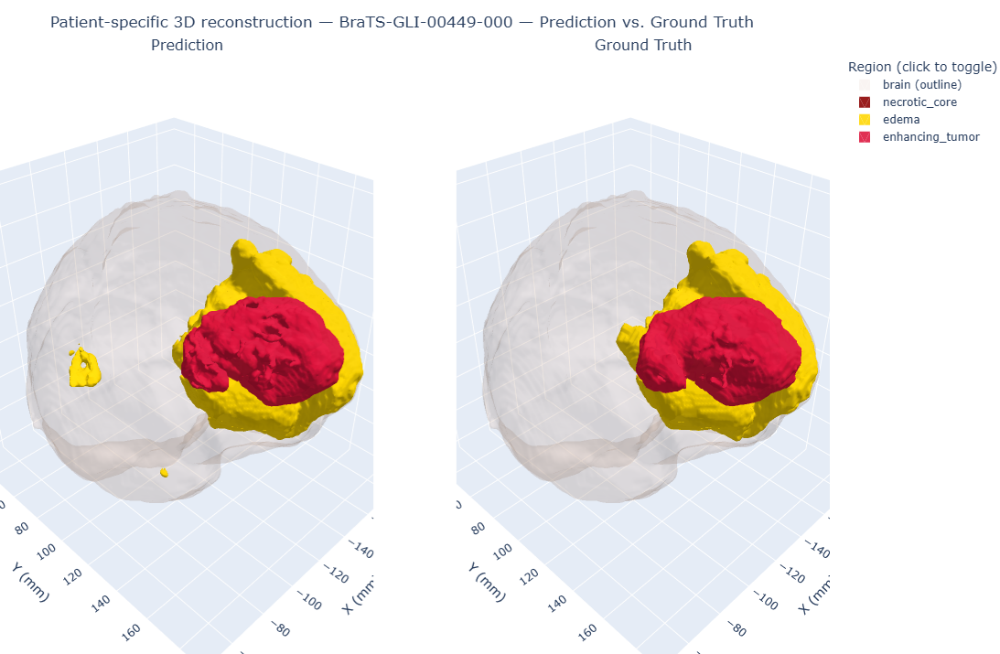

In [80]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

REGION_COLORS = {
    "necrotic_core": "rgb(139, 0, 0)",
    "edema": "rgb(255, 215, 0)",
    "enhancing_tumor": "rgb(220, 20, 60)",
}
DEFAULT_COLOR_CYCLE = ["rgb(31,119,180)", "rgb(44,160,44)", "rgb(148,103,189)", "rgb(140,86,75)"]
BRAIN_COLOR = "rgb(225, 200, 185)"  # pale tissue tone
BRAIN_OPACITY = 0.18                # low opacity so tumor regions show through

# Gentle surface lighting so meshes read as organic tissue rather than flat clip-art shapes.
MESH_LIGHTING = dict(ambient=0.55, diffuse=0.8, specular=0.25, roughness=0.6, fresnel=0.1)
MESH_LIGHTPOSITION = dict(x=100, y=200, z=150)

def _add_mesh_traces(fig, meshes, brain_mesh, scene_id, showlegend):
    if brain_mesh is not None:
        bverts, bfaces = brain_mesh["vertices_mm"], brain_mesh["faces"]
        fig.add_trace(go.Mesh3d(
            x=bverts[:, 0], y=bverts[:, 1], z=bverts[:, 2],
            i=bfaces[:, 0], j=bfaces[:, 1], k=bfaces[:, 2],
            color=BRAIN_COLOR, opacity=BRAIN_OPACITY, name="brain (outline)",
            showlegend=showlegend, flatshading=False,
            lighting=MESH_LIGHTING, lightposition=MESH_LIGHTPOSITION,
        ), row=1, col=scene_id)

    for i, (label_name, mesh) in enumerate(meshes.items()):
        verts, faces = mesh["vertices_mm"], mesh["faces"]
        color = REGION_COLORS.get(label_name, DEFAULT_COLOR_CYCLE[i % len(DEFAULT_COLOR_CYCLE)])
        fig.add_trace(go.Mesh3d(
            x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
            i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
            color=color, opacity=0.88, name=label_name,
            showlegend=showlegend, flatshading=False,
            lighting=MESH_LIGHTING, lightposition=MESH_LIGHTPOSITION,
        ), row=1, col=scene_id)

def build_interactive_viewer(meshes, patient_id, brain_mesh=None, gt_meshes=None):
    show_comparison = bool(gt_meshes)

    if show_comparison:
        fig = make_subplots(
            rows=1, cols=2,
            specs=[[{"type": "scene"}, {"type": "scene"}]],
            subplot_titles=("Prediction", "Ground Truth"),
        )
        _add_mesh_traces(fig, meshes, brain_mesh, scene_id=1, showlegend=True)
        _add_mesh_traces(fig, gt_meshes, brain_mesh, scene_id=2, showlegend=False)

        scene_axes = dict(xaxis_title="X (mm)", yaxis_title="Y (mm)", zaxis_title="Z (mm)", aspectmode="data")
        fig.update_layout(
            title=f"Patient-specific 3D reconstruction — {patient_id} — Prediction vs. Ground Truth",
            scene=scene_axes, scene2=scene_axes,
            legend=dict(title="Region (click to toggle)"),
            width=1400, height=700,
            margin=dict(l=0, r=0, t=60, b=0),
        )
        print("Ground truth is available — showing Prediction vs. Ground Truth side by side. "
              "Visually compare tumor shape/extent between the two panels.")
    else:
        fig = go.Figure()
        if brain_mesh is not None:
            bverts, bfaces = brain_mesh["vertices_mm"], brain_mesh["faces"]
            fig.add_trace(go.Mesh3d(
                x=bverts[:, 0], y=bverts[:, 1], z=bverts[:, 2],
                i=bfaces[:, 0], j=bfaces[:, 1], k=bfaces[:, 2],
                color=BRAIN_COLOR, opacity=BRAIN_OPACITY, name="brain (outline)",
                showlegend=True, flatshading=False,
                lighting=MESH_LIGHTING, lightposition=MESH_LIGHTPOSITION,
            ))
        for i, (label_name, mesh) in enumerate(meshes.items()):
            verts, faces = mesh["vertices_mm"], mesh["faces"]
            color = REGION_COLORS.get(label_name, DEFAULT_COLOR_CYCLE[i % len(DEFAULT_COLOR_CYCLE)])
            fig.add_trace(go.Mesh3d(
                x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
                i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                color=color, opacity=0.88, name=label_name,
                showlegend=True, flatshading=False,
                lighting=MESH_LIGHTING, lightposition=MESH_LIGHTPOSITION,
            ))
        fig.update_layout(
            title=f"Patient-specific 3D tumor reconstruction — {patient_id}",
            scene=dict(xaxis_title="X (mm)", yaxis_title="Y (mm)", zaxis_title="Z (mm)", aspectmode="data"),
            legend=dict(title="Region (click to toggle)"),
            width=900, height=700,
            margin=dict(l=0, r=0, t=40, b=0),
        )
        if not has_ground_truth:
            print("No ground truth available ('new_patient' mode) — showing prediction only. "
                  "Run in 'test_patient' mode on a labeled scan to see the correctness comparison.")
        elif gt_meshes is not None and not gt_meshes:
            print("Ground truth was checked but no regions were present in it for this scan — "
                  "showing prediction only.")

    return fig

if meshes or brain_mesh is not None:
    viewer_fig = build_interactive_viewer(meshes, target_patient_id, brain_mesh=brain_mesh, gt_meshes=gt_meshes)
    viewer_fig.show()
else:
    print("No meshes to display.")


## Cell 11 — Save Mesh Files (OBJ) and the Interactive Viewer (HTML)

Saves each region's mesh as a standard `.obj` file (readable by Blender, MeshLab, and most 3D
software) and the interactive viewer as a standalone `.html` file that opens in any browser without
needing Python or Jupyter — useful for sharing a specific patient's reconstruction.


In [81]:
def save_mesh_as_obj(vertices, faces, path):
    with open(path, "w") as f:
        f.write("# MedTwin AI Phase 4 — patient-specific mesh\n")
        for v in vertices:
            f.write(f"v {v[0]:.4f} {v[1]:.4f} {v[2]:.4f}\n")
        for face in faces:
            f.write(f"f {face[0]+1} {face[1]+1} {face[2]+1}\n")

patient_mesh_dir = MESH_DIR / target_patient_id if target_patient_id else MESH_DIR
patient_mesh_dir.mkdir(parents=True, exist_ok=True)

saved_paths = []

if brain_mesh is not None:
    brain_obj_path = patient_mesh_dir / "brain_outline.obj"
    save_mesh_as_obj(brain_mesh["vertices_mm"], brain_mesh["faces"], brain_obj_path)
    saved_paths.append(brain_obj_path)
    print(f"Saved: {brain_obj_path}")

if meshes:
    for label_name, mesh in meshes.items():
        obj_path = patient_mesh_dir / f"{label_name}.obj"
        save_mesh_as_obj(mesh["vertices_mm"], mesh["faces"], obj_path)
        saved_paths.append(obj_path)
        print(f"Saved: {obj_path}")

if gt_meshes:
    for label_name, mesh in gt_meshes.items():
        obj_path = patient_mesh_dir / f"{label_name}_ground_truth.obj"
        save_mesh_as_obj(mesh["vertices_mm"], mesh["faces"], obj_path)
        saved_paths.append(obj_path)
        print(f"Saved: {obj_path}")

if prediction_vs_gt_df is not None:
    comparison_csv_path = patient_mesh_dir / f"{target_patient_id}_prediction_vs_ground_truth.csv"
    prediction_vs_gt_df.to_csv(comparison_csv_path, index=False)
    print(f"Saved: {comparison_csv_path}")

if meshes or brain_mesh is not None:
    html_path = patient_mesh_dir / f"{target_patient_id}_interactive_viewer.html"
    viewer_fig.write_html(str(html_path))
    print(f"Saved interactive viewer: {html_path}")
else:
    print("No meshes to save.")


Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\brain_outline.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\necrotic_core.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\edema.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\enhancing_tumor.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\necrotic_core_ground_truth.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\edema_ground_truth.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\enhancing_tumor_ground_truth.obj
Saved: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000\BraTS-GLI-00449-000_prediction_vs_ground_truth.csv
Saved interactive viewer: C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\p

## Cell 12 — Final Summary and Next Phase


In [82]:
def print_phase4_summary():
    print("=" * 60)
    print("PHASE 4 — 3D RECONSTRUCTION & VIEWER READINESS REPORT")
    print("=" * 60)

    checks = {
        "Model bundle loaded": model_bundle is not None,
        "Model weights loaded": model_loaded_ok,
        "Patient-specific inference produced a prediction": prediction_labels is not None,
        "Brain outline extracted": brain_mesh is not None,
        "At least one tumor mesh extracted": bool(meshes),
        "Interactive viewer rendered": bool(meshes) or brain_mesh is not None,
        "Mesh files saved": bool(saved_paths),
    }
    for name, passed in checks.items():
        print(f"  [{'PASS' if passed else 'FAIL'}] {name}")

    print(f"\nPatient:            {target_patient_id}")
    print(f"Brain outline:       {'generated' if brain_mesh is not None else 'not available'}")
    print(f"Tumor regions reconstructed: {list(meshes.keys()) if meshes else 'none'}")
    print(f"Mesh output folder:  {patient_mesh_dir}")

    print(f"\nCorrectness check (prediction vs. ground truth): ", end="")
    if prediction_vs_gt_df is not None:
        n_close = (prediction_vs_gt_df["verdict"] == "Close match").sum()
        n_total = len(prediction_vs_gt_df)
        print(f"{n_close}/{n_total} regions are a close match to ground truth (see Cell 9b).")
    else:
        print("not available for this patient (no ground truth — run in 'test_patient' mode "
              "on a labeled scan to check correctness).")

    all_passed = all(checks.values())
    print()
    if all_passed:
        print("PHASE 4 3D RECONSTRUCTION & VIEWER READY")
    else:
        print("Pipeline is NOT fully ready — resolve the FAILed checks above.")

    print(
        "\nReminder: this is a research prototype. The 3D reconstruction reflects this patient's "
        "AI-predicted segmentation, not a clinically validated anatomical model. A visually "
        "convincing 3D shape is NOT the same as a correct one — always check Cell 9b (or the "
        "Phase 2/3 Dice scores) before trusting the reconstruction, not just how it looks."
    )

    print("\n" + "-" * 60)
    print("Next Phase (not implemented here):")
    print("  Interactive Viewer Application / Dashboard")
    print("  Recommended: wrap this notebook's mesh + volume outputs in a lightweight web app")
    print("  (e.g. Dash/Streamlit) so a user can upload a scan and view results without Jupyter.")

print_phase4_summary()


PHASE 4 — 3D RECONSTRUCTION & VIEWER READINESS REPORT
  [PASS] Model bundle loaded
  [PASS] Model weights loaded
  [PASS] Patient-specific inference produced a prediction
  [PASS] Brain outline extracted
  [PASS] At least one tumor mesh extracted
  [PASS] Interactive viewer rendered
  [PASS] Mesh files saved

Patient:            BraTS-GLI-00449-000
Brain outline:       generated
Tumor regions reconstructed: ['necrotic_core', 'edema', 'enhancing_tumor']
Mesh output folder:  C:\Users\admin\Desktop\Med_Twin\Med_Twin\outputs\phase4_meshes\BraTS-GLI-00449-000

Correctness check (prediction vs. ground truth): 1/3 regions are a close match to ground truth (see Cell 9b).

PHASE 4 3D RECONSTRUCTION & VIEWER READY

Reminder: this is a research prototype. The 3D reconstruction reflects this patient's AI-predicted segmentation, not a clinically validated anatomical model. A visually convincing 3D shape is NOT the same as a correct one — always check Cell 9b (or the Phase 2/3 Dice scores) before tr